# Lecture Notes: Trigonometric Substitution
*Stewart, **Calculus**, §7.3*

**Learning objectives.** By the end of this lecture you should be able to:
1. Pick the right substitution for $\sqrt{a^2 - x^2}$, $\sqrt{a^2 + x^2}$ and $\sqrt{x^2 - a^2}$.
2. Turn the integral into a trigonometric integral (§7.2) and evaluate it.
3. Go back to $x$ with a reference triangle.
4. Complete the square to handle $\sqrt{ax^2 + bx + c}$.
5. Check every answer symbolically with **SymPy** and numerically with **NumPy**.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import Math, display

sp.init_printing()
x, u = sp.symbols("x u")
theta = sp.Symbol("theta")

## 1. The idea: an *inverse* substitution

In §7.2 and earlier we substituted $u = g(x)$, a new variable that is a function of the old one. Trigonometric substitution goes the other way: we write the **old** variable as a function of a new one,
$$x = a\sin\theta,\qquad dx = a\cos\theta\,d\theta.$$

Why would that help? Consider $\int\sqrt{a^2 - x^2}\,dx$. No ordinary $u$-substitution works. But with $x = a\sin\theta$ the Pythagorean identity removes the square root:
$$\sqrt{a^2 - x^2} = \sqrt{a^2 - a^2\sin^2\theta} = \sqrt{a^2\cos^2\theta} = a|\cos\theta| = a\cos\theta.$$
The last step needs $\cos\theta \ge 0$. That holds if we take $-\pi/2 \le \theta \le \pi/2$, and this restriction also makes the substitution one-to-one, so $\theta = \sin^{-1}(x/a)$.

### The three substitutions

| Expression | Substitution | Range of $\theta$ | Identity |
|---|---|---|---|
| $\sqrt{a^2 - x^2}$ | $x = a\sin\theta$ | $-\frac{\pi}{2} \le \theta \le \frac{\pi}{2}$ | $1 - \sin^2\theta = \cos^2\theta$ |
| $\sqrt{a^2 + x^2}$ | $x = a\tan\theta$ | $-\frac{\pi}{2} < \theta < \frac{\pi}{2}$ | $1 + \tan^2\theta = \sec^2\theta$ |
| $\sqrt{x^2 - a^2}$ | $x = a\sec\theta$ | $0 \le \theta < \frac{\pi}{2}$ or $\pi \le \theta < \frac{3\pi}{2}$ | $\sec^2\theta - 1 = \tan^2\theta$ |

In each case the square root becomes a single trig function with no absolute value:
$$\sqrt{a^2 - x^2} = a\cos\theta,\qquad \sqrt{a^2 + x^2} = a\sec\theta,\qquad \sqrt{x^2 - a^2} = a\tan\theta.$$

Let's confirm these with SymPy. We substitute and simplify, using a value of $\theta$ inside each range to fix the sign of the root:

In [2]:
a = sp.Symbol("a", positive=True)
cases = [
    (r"\sqrt{a^2-x^2}", sp.sqrt(a**2 - x**2), a * sp.sin(theta), a * sp.cos(theta)),
    (r"\sqrt{a^2+x^2}", sp.sqrt(a**2 + x**2), a * sp.tan(theta), a * sp.sec(theta)),
    (r"\sqrt{x^2-a^2}", sp.sqrt(x**2 - a**2), a * sp.sec(theta), a * sp.tan(theta)),
]
for name, root, sub, expected in cases:
    after = sp.trigsimp(root.subs(x, sub))
    # sqrt(cos^2) is |cos|: compare at sample angles in the allowed range to fix the sign
    ok = all(abs(float((after - expected).subs({a: 2, theta: t}))) < 1e-12 for t in [0.1, 0.5, 1.2])
    display(Math(rf"x = {sp.latex(sub)}:\quad {name} = {sp.latex(after)} = {sp.latex(expected)}\quad\text{{: {ok}}}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### A checking function

As in §7.1 and §7.2, we check each antiderivative by differentiating it. If `simplify` can't reduce $F' - f$ to $0$, we compare numerically at points where the integrand is defined.

In [3]:
def check(F, integrand, var=x, pts=(0.3, 0.7, 1.1, 1.9, -0.4)):
    # Verify F' = integrand: symbolically first, then numerically at sample points
    diff = sp.diff(F, var) - integrand
    ok = sp.simplify(diff) == 0
    if not ok:
        ok = all(abs(complex(diff.subs(var, p).evalf())) < 1e-10 for p in pts)
    print("d/dx(answer) == integrand:", ok)
    return ok

### Going back to $x$: the reference triangle

After integrating we have an answer in $\theta$, and we need it in $x$. Draw a right triangle that encodes the substitution. For $x = a\sin\theta$, $\sin\theta = x/a$ = opposite/hypotenuse, so label the opposite side $x$ and the hypotenuse $a$. Pythagoras gives the adjacent side $\sqrt{a^2 - x^2}$. Every other trig function of $\theta$ can then be read off the triangle.

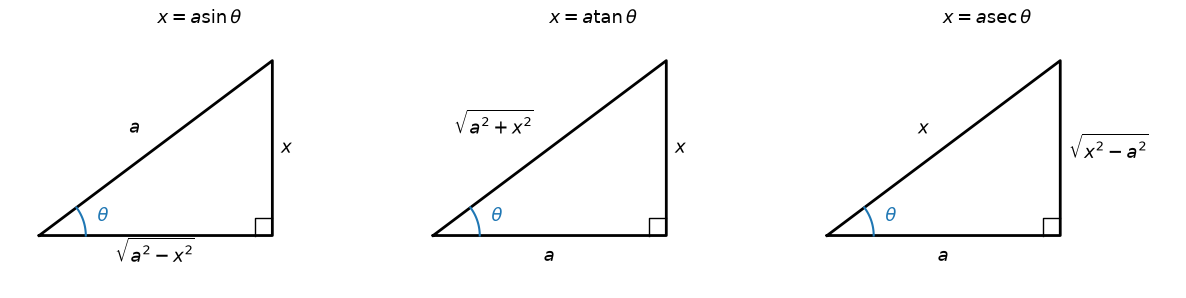

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
triangles = [
    (r"$x = a\sin\theta$", r"$\sqrt{a^2-x^2}$", r"$x$", r"$a$"),
    (r"$x = a\tan\theta$", r"$a$", r"$x$", r"$\sqrt{a^2+x^2}$"),
    (r"$x = a\sec\theta$", r"$a$", r"$\sqrt{x^2-a^2}$", r"$x$"),
]
for ax, (title, adj, opp, hyp) in zip(axes, triangles):
    ax.plot([0, 4, 4, 0], [0, 0, 3, 0], "k", lw=2)
    ax.plot([3.7, 3.7, 4], [0, 0.3, 0.3], "k", lw=1)          # right-angle mark
    arc = np.linspace(0, np.arctan2(3, 4), 30)
    ax.plot(0.8 * np.cos(arc), 0.8 * np.sin(arc), "C0")
    ax.text(1.0, 0.25, r"$\theta$", color="C0", fontsize=13)
    ax.text(2, -0.45, adj, ha="center", fontsize=13)
    ax.text(4.15, 1.5, opp, va="center", fontsize=13)
    ax.text(1.75, 1.75, hyp, ha="right", fontsize=13)
    ax.set_title(title, fontsize=13)
    ax.set_xlim(-0.5, 6); ax.set_ylim(-0.9, 3.5)
    ax.set_aspect("equal"); ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Expressions $\sqrt{a^2 - x^2}$: use $x = a\sin\theta$

### Example 1: $\displaystyle\int\frac{\sqrt{9 - x^2}}{x^2}\,dx$

Let $x = 3\sin\theta$ with $-\pi/2 \le \theta \le \pi/2$. Then $dx = 3\cos\theta\,d\theta$ and $\sqrt{9 - x^2} = 3\cos\theta$:
$$\int\frac{\sqrt{9 - x^2}}{x^2}\,dx = \int\frac{3\cos\theta}{9\sin^2\theta}\,3\cos\theta\,d\theta = \int\cot^2\theta\,d\theta = \int(\csc^2\theta - 1)\,d\theta = -\cot\theta - \theta + C.$$

**Back to $x$.** From the triangle with opposite side $x$ and hypotenuse $3$, the adjacent side is $\sqrt{9 - x^2}$, so $\cot\theta = \dfrac{\sqrt{9 - x^2}}{x}$. Also $\theta = \sin^{-1}(x/3)$:
$$\int\frac{\sqrt{9 - x^2}}{x^2}\,dx = -\frac{\sqrt{9 - x^2}}{x} - \sin^{-1}\Big(\frac{x}{3}\Big) + C.$$

In SymPy we do the same steps: write the integrand in $\theta$, integrate, and substitute $\theta = \sin^{-1}(x/3)$. SymPy reads off the triangle for us, since it simplifies $\cot(\sin^{-1}(x/3))$ automatically.

In [5]:
integrand_theta = (3 * sp.cos(theta)) / (9 * sp.sin(theta)**2) * 3 * sp.cos(theta)
display(Math(r"\int\frac{\sqrt{9-x^2}}{x^2}\,dx = \int " + sp.latex(sp.simplify(integrand_theta)) + r"\,d\theta"))
G = sp.integrate(sp.cot(theta)**2, theta)
display(Math(r"\int\cot^2\theta\,d\theta = " + sp.latex(G) + " + C"))
F = G.subs(theta, sp.asin(x / 3))
display(Math(r"\int\frac{\sqrt{9-x^2}}{x^2}\,dx = " + sp.latex(F) + " + C"))
check(F, sp.sqrt(9 - x**2) / x**2);

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


### Example 2: the area of an ellipse

Find the area enclosed by $\dfrac{x^2}{a^2} + \dfrac{y^2}{b^2} = 1$.

Solving for $y$, the upper half is $y = \dfrac{b}{a}\sqrt{a^2 - x^2}$. By symmetry the area is four times the area in the first quadrant:
$$A = \frac{4b}{a}\int_0^a\sqrt{a^2 - x^2}\,dx.$$
Let $x = a\sin\theta$. The limits change too: $x = 0 \Rightarrow \theta = 0$, and $x = a \Rightarrow \theta = \pi/2$. So we never have to go back to $x$:
$$A = \frac{4b}{a}\int_0^{\pi/2}a\cos\theta\cdot a\cos\theta\,d\theta = 4ab\int_0^{\pi/2}\cos^2\theta\,d\theta = 2ab\Big[\theta + \tfrac12\sin 2\theta\Big]_0^{\pi/2} = \pi ab.$$
When $a = b = r$ this is the area of a circle, $\pi r^2$.

In [6]:
b = sp.Symbol("b", positive=True)
A_theta = 4 * a * b * sp.integrate(sp.cos(theta)**2, (theta, 0, sp.pi / 2))
A_direct = 4 * b / a * sp.integrate(sp.sqrt(a**2 - x**2), (x, 0, a))
display(Math(r"A = 4ab\int_0^{\pi/2}\cos^2\theta\,d\theta = " + sp.latex(A_theta)
             + r"\qquad\text{SymPy in } x\text{: } " + sp.latex(sp.simplify(A_direct))))

a_val, b_val = 3.0, 2.0
xs = np.linspace(0, a_val, 200_001)
print(f"a = 3, b = 2:  π·a·b = {np.pi * a_val * b_val:.6f},  NumPy trapezoid: {4 * np.trapezoid(b_val / a_val * np.sqrt(a_val**2 - xs**2), xs):.6f}")

<IPython.core.display.Math object>

a = 3, b = 2:  π·a·b = 18.849556,  NumPy trapezoid: 18.849556


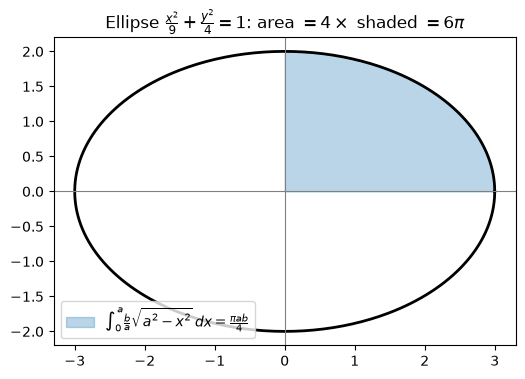

In [7]:
t = np.linspace(0, 2 * np.pi, 400)
xs_q = np.linspace(0, a_val, 200)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(a_val * np.cos(t), b_val * np.sin(t), "k", lw=2)
ax.fill_between(xs_q, 0, b_val / a_val * np.sqrt(a_val**2 - xs_q**2), alpha=0.3, color="C0",
                label=r"$\int_0^a \frac{b}{a}\sqrt{a^2-x^2}\,dx = \frac{\pi ab}{4}$")
ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
ax.set_aspect("equal")
ax.set_title(r"Ellipse $\frac{x^2}{9}+\frac{y^2}{4}=1$: area $= 4\times$ shaded $= 6\pi$")
ax.legend(loc="lower left", fontsize=10)
plt.show()

## 3. Expressions $\sqrt{a^2 + x^2}$: use $x = a\tan\theta$

### Example 3: $\displaystyle\int\frac{dx}{x^2\sqrt{x^2 + 4}}$

Let $x = 2\tan\theta$ with $-\pi/2 < \theta < \pi/2$. Then $dx = 2\sec^2\theta\,d\theta$ and $\sqrt{x^2 + 4} = 2\sec\theta$:
$$\int\frac{dx}{x^2\sqrt{x^2 + 4}} = \int\frac{2\sec^2\theta}{4\tan^2\theta\cdot 2\sec\theta}\,d\theta = \frac14\int\frac{\sec\theta}{\tan^2\theta}\,d\theta.$$
Write it in sines and cosines: $\dfrac{\sec\theta}{\tan^2\theta} = \dfrac{1}{\cos\theta}\cdot\dfrac{\cos^2\theta}{\sin^2\theta} = \dfrac{\cos\theta}{\sin^2\theta}$. With $u = \sin\theta$:
$$\frac14\int\frac{\cos\theta}{\sin^2\theta}\,d\theta = \frac14\int\frac{du}{u^2} = -\frac{1}{4u} + C = -\frac{\csc\theta}{4} + C.$$

**Back to $x$.** $\tan\theta = x/2$: opposite $x$, adjacent $2$, hypotenuse $\sqrt{x^2 + 4}$. So $\csc\theta = \sqrt{x^2 + 4}/x$ and
$$\int\frac{dx}{x^2\sqrt{x^2 + 4}} = -\frac{\sqrt{x^2 + 4}}{4x} + C.$$

In [8]:
integrand_theta = 2 * sp.sec(theta)**2 / (4 * sp.tan(theta)**2 * 2 * sp.sec(theta))
display(Math(r"\int\frac{dx}{x^2\sqrt{x^2+4}} = \int " + sp.latex(sp.simplify(integrand_theta)) + r"\,d\theta"))
G = sp.integrate(sp.cos(theta) / sp.sin(theta)**2, theta) / 4
F = G.subs(theta, sp.atan(x / 2))
display(Math(r"= " + sp.latex(G) + r" + C = " + sp.latex(sp.simplify(F)) + " + C"))
check(F, 1 / (x**2 * sp.sqrt(x**2 + 4)));

<IPython.core.display.Math object>

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


### Example 4: $\displaystyle\int\frac{x}{\sqrt{x^2 + 4}}\,dx$ (don't overdo it)

We *could* use $x = 2\tan\theta$, but the numerator $x$ is almost the derivative of $x^2 + 4$. The ordinary substitution $u = x^2 + 4$, $du = 2x\,dx$ is much faster:
$$\int\frac{x}{\sqrt{x^2 + 4}}\,dx = \frac12\int u^{-1/2}\,du = \sqrt{u} + C = \sqrt{x^2 + 4} + C.$$
**Always check for a simple substitution first.** Trig substitution is for when the root doesn't come with its inner derivative.

In [9]:
F = sp.sqrt(x**2 + 4)
display(Math(r"\int\frac{x}{\sqrt{x^2+4}}\,dx = " + sp.latex(F) + " + C"))
check(F, x / sp.sqrt(x**2 + 4))

# The trig-substitution route gives the same answer, just with more work
G = sp.integrate(sp.tan(theta) * sp.sec(theta) * 2, theta)     # 2 tanθ · 2sec²θ / (2secθ)
display(Math(r"x = 2\tan\theta:\quad \int 2\tan\theta\sec\theta\,d\theta = " + sp.latex(G)
             + r" = " + sp.latex(sp.simplify(G.subs(theta, sp.atan(x / 2)))) + " + C"));

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


<IPython.core.display.Math object>

## 4. Expressions $\sqrt{x^2 - a^2}$: use $x = a\sec\theta$

### Example 5: $\displaystyle\int\frac{dx}{\sqrt{x^2 - a^2}}$, where $a > 0$

Let $x = a\sec\theta$ with $0 < \theta < \pi/2$ or $\pi < \theta < 3\pi/2$. Then $dx = a\sec\theta\tan\theta\,d\theta$ and $\sqrt{x^2 - a^2} = a\tan\theta$:
$$\int\frac{dx}{\sqrt{x^2 - a^2}} = \int\frac{a\sec\theta\tan\theta}{a\tan\theta}\,d\theta = \int\sec\theta\,d\theta = \ln|\sec\theta + \tan\theta| + C.$$
(The integral of $\sec\theta$ is from §7.2.)

**Back to $x$.** $\sec\theta = x/a$: hypotenuse $x$, adjacent $a$, opposite $\sqrt{x^2 - a^2}$. So $\tan\theta = \sqrt{x^2 - a^2}/a$ and
$$\int\frac{dx}{\sqrt{x^2 - a^2}} = \ln\left|\frac{x}{a} + \frac{\sqrt{x^2 - a^2}}{a}\right| + C = \ln\left|x + \sqrt{x^2 - a^2}\right| + C_1,$$
where $C_1 = C - \ln a$. The constant $\ln a$ is absorbed into the arbitrary constant.

In [10]:
G = sp.log(sp.sec(theta) + sp.tan(theta))
F = sp.log(x + sp.sqrt(x**2 - a**2))
display(Math(r"\int\sec\theta\,d\theta = " + sp.latex(G) + r"\quad\Longrightarrow\quad \int\frac{dx}{\sqrt{x^2-a^2}} = " + sp.latex(F) + " + C"))
check(F, 1 / sp.sqrt(x**2 - a**2), pts=())       # symbolic check, for any a > 0

# Numerical check for a = 2 on [3, 5]
xs = np.linspace(3, 5, 100_001)
exact = np.log(5 + np.sqrt(21)) - np.log(3 + np.sqrt(5))
print(f"a = 2:  ∫_3^5 dx/√(x²-4) = {exact:.8f},  NumPy trapezoid: {np.trapezoid(1 / np.sqrt(xs**2 - 4), xs):.8f}")

<IPython.core.display.Math object>

d/dx(answer) == integrand: True
a = 2:  ∫_3^5 dx/√(x²-4) = 0.60437559,  NumPy trapezoid: 0.60437559


### Example 6: $\displaystyle\int_0^{3\sqrt3/2}\frac{x^3}{(4x^2 + 9)^{3/2}}\,dx$

The fractional power is still a square root: $(4x^2 + 9)^{3/2} = \big(\sqrt{4x^2 + 9}\big)^3$. Here $4x^2 + 9 = (2x)^2 + 3^2$, so let $2x = 3\tan\theta$, that is $x = \tfrac32\tan\theta$. Then
$$dx = \tfrac32\sec^2\theta\,d\theta,\qquad \sqrt{4x^2 + 9} = \sqrt{9\tan^2\theta + 9} = 3\sec\theta.$$
New limits: $x = 0 \Rightarrow \tan\theta = 0 \Rightarrow \theta = 0$, and $x = \tfrac{3\sqrt3}{2} \Rightarrow \tan\theta = \sqrt3 \Rightarrow \theta = \tfrac{\pi}{3}$.
$$\int_0^{3\sqrt3/2}\frac{x^3}{(4x^2 + 9)^{3/2}}\,dx = \int_0^{\pi/3}\frac{\tfrac{27}{8}\tan^3\theta}{27\sec^3\theta}\cdot\tfrac32\sec^2\theta\,d\theta = \frac{3}{16}\int_0^{\pi/3}\frac{\tan^3\theta}{\sec\theta}\,d\theta = \frac{3}{16}\int_0^{\pi/3}\frac{\sin^3\theta}{\cos^2\theta}\,d\theta.$$
This is a §7.2 integral with an odd power of sine. Save one $\sin\theta$ and let $u = \cos\theta$, $du = -\sin\theta\,d\theta$. The limits become $u = 1$ and $u = \tfrac12$:
$$\frac{3}{16}\int_0^{\pi/3}\frac{1 - \cos^2\theta}{\cos^2\theta}\sin\theta\,d\theta = \frac{3}{16}\int_{1/2}^{1}\frac{1 - u^2}{u^2}\,du = \frac{3}{16}\Big[-\frac1u - u\Big]_{1/2}^{1} = \frac{3}{16}\Big[(-2) - \big(-\tfrac52\big)\Big] = \frac{3}{32}.$$

In [11]:
step_theta = sp.Rational(3, 16) * sp.integrate(sp.sin(theta)**3 / sp.cos(theta)**2, (theta, 0, sp.pi / 3))
step_u = sp.Rational(3, 16) * sp.integrate((1 - u**2) / u**2, (u, sp.Rational(1, 2), 1))
direct = sp.integrate(x**3 / (4 * x**2 + 9)**sp.Rational(3, 2), (x, 0, 3 * sp.sqrt(3) / 2))
display(Math(r"\text{in }\theta: " + sp.latex(sp.simplify(step_theta)) + r",\quad \text{in } u: " + sp.latex(step_u)
             + r",\quad \text{SymPy in } x: " + sp.latex(sp.simplify(direct))))

xs = np.linspace(0, 3 * np.sqrt(3) / 2, 100_001)
print(f"3/32 = {3 / 32:.10f},  NumPy trapezoid: {np.trapezoid(xs**3 / (4 * xs**2 + 9)**1.5, xs):.10f}")

<IPython.core.display.Math object>

3/32 = 0.0937500000,  NumPy trapezoid: 0.0937500000


## 5. Completing the square

When the expression under the root is a general quadratic $ax^2 + bx + c$, complete the square first. It then becomes one of the three forms.

### Example 7: $\displaystyle\int\frac{x}{\sqrt{3 - 2x - x^2}}\,dx$

Complete the square:
$$3 - 2x - x^2 = 3 - (x^2 + 2x) = 3 + 1 - (x^2 + 2x + 1) = 4 - (x + 1)^2.$$
Let $u = x + 1$, so $x = u - 1$ and $du = dx$:
$$\int\frac{x}{\sqrt{3 - 2x - x^2}}\,dx = \int\frac{u - 1}{\sqrt{4 - u^2}}\,du.$$
This is the $\sqrt{a^2 - u^2}$ form with $a = 2$. Let $u = 2\sin\theta$, $du = 2\cos\theta\,d\theta$, $\sqrt{4 - u^2} = 2\cos\theta$:
$$\int\frac{2\sin\theta - 1}{2\cos\theta}\,2\cos\theta\,d\theta = \int(2\sin\theta - 1)\,d\theta = -2\cos\theta - \theta + C.$$
**Back to $x$.** $\sin\theta = u/2$, so $\cos\theta = \sqrt{4 - u^2}/2$ and $\theta = \sin^{-1}(u/2)$:
$$\int\frac{x}{\sqrt{3 - 2x - x^2}}\,dx = -\sqrt{4 - u^2} - \sin^{-1}\Big(\frac u2\Big) + C = -\sqrt{3 - 2x - x^2} - \sin^{-1}\Big(\frac{x + 1}{2}\Big) + C.$$

In [12]:
q = 3 - 2 * x - x**2
display(Math(sp.latex(q) + " = " + sp.latex(4 - (x + 1)**2) + r"\quad\text{: }" + str(sp.expand(q - (4 - (x + 1)**2)) == 0)))

G = sp.integrate(2 * sp.sin(theta) - 1, theta)
F = G.subs(theta, sp.asin(u / 2)).subs(u, x + 1)
display(Math(r"\int(2\sin\theta - 1)\,d\theta = " + sp.latex(G) + r"\quad\Longrightarrow\quad \int\frac{x}{\sqrt{3-2x-x^2}}\,dx = " + sp.latex(F) + " + C"))
check(F, x / sp.sqrt(q), pts=(-2.5, -1.2, 0.0, 0.4, 0.8));     # 3 - 2x - x² > 0 for -3 < x < 1

<IPython.core.display.Math object>

<IPython.core.display.Math object>

d/dx(answer) == integrand:

 True


## 6. Common mistakes

1. **Forgetting $dx$.** With $x = a\sin\theta$, $dx = a\cos\theta\,d\theta$. Replacing $dx$ by $d\theta$ is the most common error.
2. **Picking the wrong substitution.** Match the sign pattern: $a^2 - x^2 \to \sin$, $a^2 + x^2 \to \tan$, $x^2 - a^2 \to \sec$.
3. **Leaving the answer in $\theta$.** An indefinite integral in $x$ needs an answer in $x$. Use the triangle.
4. **Not changing the limits** in a definite integral. Either change them to $\theta$-values (Examples 2 and 6) or go back to $x$ first, but don't mix the two.
5. **Using trig substitution when a simple one works**, as in Example 4.
6. **Coefficients in front of $x^2$.** For $\sqrt{9 - 4x^2}$, set $2x = 3\sin\theta$, so $x = \tfrac32\sin\theta$ (not $x = 3\sin\theta$).

Here is mistake 6 checked: with $x = \tfrac32\sin\theta$ the root simplifies, with $x = 3\sin\theta$ it doesn't.

In [13]:
for sub in [sp.Rational(3, 2) * sp.sin(theta), 3 * sp.sin(theta)]:
    root = sp.trigsimp(sp.sqrt(9 - 4 * sub**2))
    display(Math(rf"x = {sp.latex(sub)}:\quad \sqrt{{9-4x^2}} = {sp.latex(root)}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 7. Practice problems

Try each by hand first, then compare with the answers below. Each answer is checked by differentiating it at points where the integrand is defined. If yours looks different, run `check` on it: it may differ only by a constant.

1. $\displaystyle\int\frac{x^2}{\sqrt{9 - x^2}}\,dx$
2. $\displaystyle\int\frac{dx}{(x^2 + 1)^{3/2}}$
3. $\displaystyle\int\frac{\sqrt{x^2 - 4}}{x}\,dx$
4. $\displaystyle\int\frac{dx}{x^2\sqrt{16 - x^2}}$
5. $\displaystyle\int\frac{dx}{\sqrt{x^2 + 2x + 5}}$
6. $\displaystyle\int_0^{1}\sqrt{1 + x^2}\,dx$
7. $\displaystyle\int_0^{2/3}\sqrt{4 - 9x^2}\,dx$

In [14]:
# (integrand, answer, sample points inside the domain)
problems = [
    (x**2 / sp.sqrt(9 - x**2), sp.Rational(9, 2) * sp.asin(x / 3) - x * sp.sqrt(9 - x**2) / 2, (0.5, 1.5, -2.0)),
    (1 / (x**2 + 1)**sp.Rational(3, 2), x / sp.sqrt(x**2 + 1), (0.3, 1.0, -2.0)),
    (sp.sqrt(x**2 - 4) / x, sp.sqrt(x**2 - 4) - 2 * sp.asec(x / 2), (2.5, 3.0, 5.0)),
    (1 / (x**2 * sp.sqrt(16 - x**2)), -sp.sqrt(16 - x**2) / (16 * x), (0.5, 3.0, -1.0)),
    (1 / sp.sqrt(x**2 + 2 * x + 5), sp.log(x + 1 + sp.sqrt(x**2 + 2 * x + 5)), (-3.0, 0.0, 2.0)),
]
for p, F, pts in problems:
    display(Math(r"\int " + sp.latex(p) + r"\,dx = " + sp.latex(F) + " + C"))
    check(F, p, pts=pts)

definite = [
    (sp.sqrt(1 + x**2), 0, 1, lambda t: np.sqrt(1 + t**2)),
    (sp.sqrt(4 - 9 * x**2), 0, sp.Rational(2, 3), lambda t: np.sqrt(np.maximum(4 - 9 * t**2, 0))),
]
for p, lo, hi, fn in definite:
    val = sp.integrate(p, (x, lo, hi))
    xs = np.linspace(float(lo), float(hi), 200_001)
    display(Math(rf"\int_{{{sp.latex(lo)}}}^{{{sp.latex(hi)}}} " + sp.latex(p) + r"\,dx = "
                 + sp.latex(sp.simplify(val)) + rf" \approx {float(val):.6f}"))
    print(f"NumPy check: {np.trapezoid(fn(xs), xs):.6f}")

<IPython.core.display.Math object>

d/dx(answer) == integrand: True


<IPython.core.display.Math object>

d/dx(answer) == integrand: True


<IPython.core.display.Math object>

...

d/dx(answer) == integrand: True


<IPython.core.display.Math object>

NumPy check: 1.147794


<IPython.core.display.Math object>

NumPy check: 1.047198


## Summary

| Expression | Substitution | $dx$ | Root becomes | Triangle |
|---|---|---|---|---|
| $\sqrt{a^2 - x^2}$ | $x = a\sin\theta$ | $a\cos\theta\,d\theta$ | $a\cos\theta$ | opp $x$, hyp $a$, adj $\sqrt{a^2 - x^2}$ |
| $\sqrt{a^2 + x^2}$ | $x = a\tan\theta$ | $a\sec^2\theta\,d\theta$ | $a\sec\theta$ | opp $x$, adj $a$, hyp $\sqrt{a^2 + x^2}$ |
| $\sqrt{x^2 - a^2}$ | $x = a\sec\theta$ | $a\sec\theta\tan\theta\,d\theta$ | $a\tan\theta$ | hyp $x$, adj $a$, opp $\sqrt{x^2 - a^2}$ |
| $\sqrt{ax^2 + bx + c}$ | complete the square first | | | |

**The steps:**
1. Check for a simple $u$-substitution first.
2. Choose the substitution from the table (complete the square if needed).
3. Replace $x$, $dx$ and the root. The integral becomes a trigonometric integral (§7.2).
4. Integrate in $\theta$.
5. Go back to $x$ with the triangle, or change the limits for a definite integral.

$$\int\frac{dx}{\sqrt{x^2 - a^2}} = \ln\left|x + \sqrt{x^2 - a^2}\right| + C,\qquad \int\sqrt{a^2 - x^2}\,dx\Big|_0^a = \frac{\pi a^2}{4}$$